<a href="https://colab.research.google.com/github/muskan-cloud/research-and-learning-ai/blob/main/experiments/fraud-classification/fraud-classification-pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fraud Classification: Imbalance, Scaling, SMOTE & Evaluation

**Intelligence Lab · Month 1 · Practical notebook 01**

In this notebook, you will build and evaluate a fraud classifier while practising:
- confusion matrix, precision, recall, F1-score and accuracy;
- train/test splitting without leakage;
- fitting `StandardScaler` on training data only;
- applying SMOTE only to training data;
- comparing a baseline with a resampled model;
- understanding the precision–recall trade-off.

**How to use:** Run the setup and data cells. In cells marked **Your turn**, write the missing code before looking up anything. Keep the test set untouched until evaluation.

You can open this notebook in Google Colab using the badge/link in the repository, or download it and run it locally in Jupyter.

In [14]:
# Install the one extra package used for SMOTE and leakage-safe pipelines
%pip -q install imbalanced-learn

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    PrecisionRecallDisplay, average_precision_score
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
print('Setup complete')

Setup complete


## 1. Create an imbalanced dataset

We will use a synthetic dataset so the notebook runs without downloading private or sensitive transaction data. The minority class represents fraud. These rows are simulated, not real transactions.

In [16]:
X, y = make_classification(
    n_samples=10_000,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    n_clusters_per_class=2,
    weights=[0.99, 0.01],
    flip_y=0.001,
    class_sep=1.0,
    random_state=RANDOM_STATE
)

feature_names = [
    'transaction_amount', 'transactions_per_hour', 'account_age_days',
    'distance_from_usual_km', 'failed_attempts', 'merchant_risk',
    'device_change_score', 'hour_of_day'
]
X = pd.DataFrame(X, columns=feature_names)
y = pd.Series(y, name='is_fraud')

print('Dataset shape:', X.shape)
print('\nClass counts:')
print(y.value_counts().rename(index={0:'Legitimate', 1:'Fraud'}))
print('\nFraud percentage:', round(y.mean() * 100, 2), '%')

Dataset shape: (10000, 8)

Class counts:
is_fraud
Legitimate    9895
Fraud          105
Name: count, dtype: int64

Fraud percentage: 1.05 %


### Checkpoint 1

1. Which class is the minority class?
2. Why could accuracy be misleading on this dataset?
3. What would a model that predicts every row as legitimate score on accuracy?

## 2. Split first — protect the test set

We split before learning preprocessing statistics or generating synthetic examples. `stratify=y` keeps the class proportions approximately consistent in both sets.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Training rows:', len(X_train))
print('Test rows:', len(X_test))
print('\nTraining fraud rate:', round(y_train.mean() * 100, 2), '%')
print('Test fraud rate:', round(y_test.mean() * 100, 2), '%')

Training rows: 8000
Test rows: 2000

Training fraud rate: 1.05 %
Test fraud rate: 1.05 %


## 3. Baseline model — no SMOTE yet

First, establish a baseline. This model uses class-imbalance-unaware logistic regression. We will fit the scaler on training data only, then transform both sets with the same fitted scaler.

In [18]:
scaler_baseline = StandardScaler()

# Fit ONLY on training features
X_train_scaled = scaler_baseline.fit_transform(X_train)

# Transform test features using training-set statistics
X_test_scaled = scaler_baseline.transform(X_test)

baseline_model = LogisticRegression(max_iter=2_000, random_state=RANDOM_STATE)
baseline_model.fit(X_train_scaled, y_train)
baseline_pred = baseline_model.predict(X_test_scaled)

print('Baseline model trained.')

Baseline model trained.


In [19]:
def evaluate_classifier(y_true, y_pred, model_name):
    results = {
        'model': model_name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
    }
    print(pd.Series(results).to_string())
    print('\nConfusion matrix [[TN, FP], [FN, TP]]:')
    print(confusion_matrix(y_true, y_pred))
    return results

baseline_results = evaluate_classifier(y_test, baseline_pred, 'Baseline logistic regression')

model        Baseline logistic regression
accuracy                             0.99
precision                             1.0
recall                           0.047619
f1                               0.090909

Confusion matrix [[TN, FP], [FN, TP]]:
[[1979    0]
 [  20    1]]


### Your turn 1 — interpret the baseline

Write down:
- Is accuracy alone a useful summary here?
- How many fraud cases did the model miss? (Read FN from the confusion matrix.)
- For this bank scenario, which error is more costly: FP or FN? Explain your assumption.

## 4. Apply SMOTE correctly

SMOTE creates synthetic minority-class examples using nearby minority examples. Because it uses distances, scaling first is important for this dataset.

For this first demonstration, we will explicitly show the steps. The scaler is fitted only on the training set. SMOTE is applied only to the scaled training set. The test set is never resampled.

In [20]:
# Fit scaler on training data only
scaler_smote = StandardScaler()
X_train_scaled_smote = scaler_smote.fit_transform(X_train)
X_test_scaled_smote = scaler_smote.transform(X_test)

# Resample only the training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled_smote, y_train
)

print('Before SMOTE:', y_train.value_counts().to_dict())
print('After SMOTE: ', pd.Series(y_train_resampled).value_counts().to_dict())
print('Test set unchanged:', X_test_scaled_smote.shape, y_test.shape)

Before SMOTE: {0: 7916, 1: 84}
After SMOTE:  {0: 7916, 1: 7916}
Test set unchanged: (2000, 8) (2000,)


In [21]:
smote_model = LogisticRegression(max_iter=2_000, random_state=RANDOM_STATE)
smote_model.fit(X_train_resampled, y_train_resampled)
smote_pred = smote_model.predict(X_test_scaled_smote)

smote_results = evaluate_classifier(y_test, smote_pred, 'Scaled + SMOTE + logistic regression')

model        Scaled + SMOTE + logistic regression
accuracy                                    0.758
precision                                0.036072
recall                                   0.857143
f1                                       0.069231

Confusion matrix [[TN, FP], [FN, TP]]:
[[1498  481]
 [   3   18]]


### Your turn 2 — compare the models

Compare baseline and SMOTE results:
1. Did recall improve?
2. What happened to precision?
3. Did accuracy increase or decrease?
4. Which model would you choose for a bank, and what operational cost would your choice create?

There is no universally best result. The right choice depends on the cost of missed fraud, false alarms, and investigation capacity.

## 5. Use a pipeline for safer model evaluation

For cross-validation and production-style workflows, put preprocessing and SMOTE inside an `imblearn` pipeline. This ensures each training fold learns its own scaling statistics and synthetic samples; validation/test rows are not used to fit those steps.

Here we fit the pipeline on the training set and evaluate once on the untouched test set.

In [22]:
safe_pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', LogisticRegression(max_iter=2_000, random_state=RANDOM_STATE))
])

safe_pipeline.fit(X_train, y_train)
pipeline_pred = safe_pipeline.predict(X_test)
pipeline_results = evaluate_classifier(y_test, pipeline_pred, 'Imbalanced-learn pipeline')

model        Imbalanced-learn pipeline
accuracy                         0.758
precision                     0.036072
recall                        0.857143
f1                            0.069231

Confusion matrix [[TN, FP], [FN, TP]]:
[[1498  481]
 [   3   18]]


## 6. Threshold experiment

A classifier can output probabilities. The default threshold is often 0.5, but we can change it to explore the precision–recall trade-off. Lower thresholds generally flag more examples as positive, often increasing recall while reducing precision.

In [23]:
fraud_probabilities = safe_pipeline.predict_proba(X_test)[:, 1]

threshold_rows = []
for threshold in [0.20, 0.35, 0.50, 0.65, 0.80]:
    threshold_pred = (fraud_probabilities >= threshold).astype(int)
    threshold_rows.append({
        'threshold': threshold,
        'precision': precision_score(y_test, threshold_pred, zero_division=0),
        'recall': recall_score(y_test, threshold_pred, zero_division=0),
        'f1': f1_score(y_test, threshold_pred, zero_division=0),
        'fraud_alerts': int(threshold_pred.sum())
    })

threshold_results = pd.DataFrame(threshold_rows)
threshold_results

,threshold,precision,recall,f1,fraud_alerts
0,0.20,0.017573,1.000000,0.034539,1195
1,0.35,0.023486,0.904762,0.045783,809
2,0.50,0.036072,0.857143,0.069231,499
3,0.65,0.043321,0.571429,0.080537,277
4,0.80,0.054264,0.333333,0.093333,129


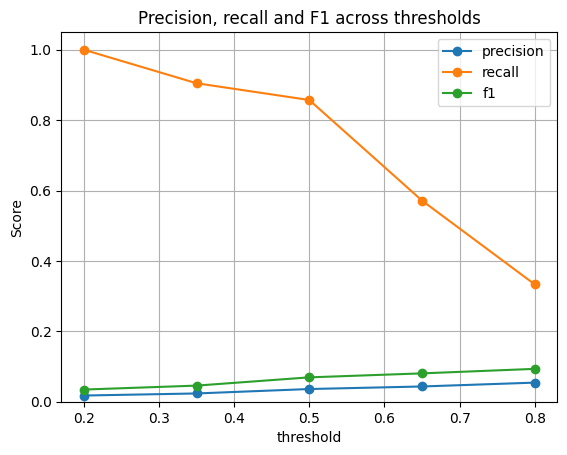

In [24]:
ax = threshold_results.plot(x='threshold', y=['precision', 'recall', 'f1'], marker='o')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Precision, recall and F1 across thresholds')
plt.grid(True)
plt.show()

### Your turn 3 — choose a threshold

Choose a threshold for a bank that strongly prioritises catching fraud. Use the table and explain:
- why you selected it;
- how many alerts it creates;
- what trade-off it makes between missed fraud and false alarms.

Do not choose a threshold from recall alone. Consider operational capacity and the costs of both error types.

## 7. Experiment 3 — class-weighted Logistic Regression

SMOTE changes the training data by generating synthetic minority-class examples. Another approach is to keep the original training rows and give mistakes on the minority class a larger penalty.

With `class_weight='balanced'`, Logistic Regression automatically assigns weights inversely related to class frequencies in the training data. This does not create new rows. It changes how strongly the model is penalised for mistakes on each class.

We will use a standard scikit-learn pipeline: fit the scaler on training data, transform features, and train the weighted classifier. The test set remains untouched.

In [25]:
from sklearn.pipeline import Pipeline

weighted_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2_000,
        random_state=RANDOM_STATE
    ))
])

weighted_pipeline.fit(X_train, y_train)
weighted_pred = weighted_pipeline.predict(X_test)

weighted_results = evaluate_classifier(
    y_test,
    weighted_pred,
    'Class-weighted logistic regression'
)

model        Class-weighted logistic regression
accuracy                                 0.7535
precision                              0.037255
recall                                 0.904762
f1                                     0.071563

Confusion matrix [[TN, FP], [FN, TP]]:
[[1488  491]
 [   2   19]]


### Your turn 4 — interpret class weighting

Compare this confusion matrix with the baseline and SMOTE results.

1. Did recall improve compared with the baseline?
2. How many false positives did it produce?
3. Is its precision better or worse than the SMOTE model?
4. Does it satisfy the bank's target of at least 90% recall and at most 100 alerts?
5. What trade-off did class weighting make?

Do not assume class weighting must outperform SMOTE. The result depends on the data and model.

## 8. Experiment 4 — threshold tuning for the class-weighted model

The default prediction uses a threshold of 0.50. We will test whether changing that threshold can reduce unnecessary alerts while preserving the bank's minimum recall target.

**Important: avoid tuning on the test set.** We first split the original training data into a smaller fit set and a validation set. We train a fresh class-weighted pipeline on the fit set, choose a threshold using validation predictions, and only then evaluate that fixed threshold on the untouched test set.

Our operational targets are:
- Recall of at least 90%.
- No more than 100 fraud alerts in this 2,000-row test set (for this exercise).

In [26]:
from sklearn.model_selection import train_test_split

# Create a validation set from the training data only.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

# Train a fresh weighted model. The final test set is not used here.
weighted_tuning_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2_000,
        random_state=RANDOM_STATE
    ))
])

weighted_tuning_pipeline.fit(X_fit, y_fit)

# Get fraud probabilities on validation data.
val_fraud_scores = weighted_tuning_pipeline.predict_proba(X_val)[:, 1]

print('Fit rows:', len(X_fit))
print('Validation rows:', len(X_val))
print('Test rows (kept untouched):', len(X_test))

Fit rows: 6400
Validation rows: 1600
Test rows (kept untouched): 2000


### 8.1 Evaluate a range of thresholds on validation data

For each threshold, count false positives, false negatives, total alerts, precision, and recall. The alert count is FP + TP: every transaction predicted as fraud becomes an alert.

In [27]:
thresholds_weighted = np.arange(0.05, 1.00, 0.05)
weighted_threshold_rows = []

for threshold in thresholds_weighted:
    val_pred = (val_fraud_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, val_pred, labels=[0, 1]).ravel()

    weighted_threshold_rows.append({
        'threshold': round(float(threshold), 2),
        'precision': precision_score(y_val, val_pred, zero_division=0),
        'recall': recall_score(y_val, val_pred, zero_division=0),
        'false_positives': int(fp),
        'false_negatives': int(fn),
        'fraud_alerts': int(fp + tp)
    })

weighted_threshold_results = pd.DataFrame(weighted_threshold_rows)
weighted_threshold_results

,threshold,precision,recall,false_positives,false_negatives,fraud_alerts
0,0.05,0.010603,0.941176,1493,1,1509
1,0.10,0.011843,0.941176,1335,1,1351
2,0.15,0.013468,0.941176,1172,1,1188
3,0.20,0.015519,0.941176,1015,1,1031
4,0.25,0.015504,0.823529,889,3,903
5,0.30,0.017677,0.823529,778,3,792
6,0.35,0.020290,0.823529,676,3,690
7,0.40,0.021812,0.764706,583,4,596
8,0.45,0.025341,0.764706,500,4,513
9,0.50,0.025000,0.647059,429,6,440


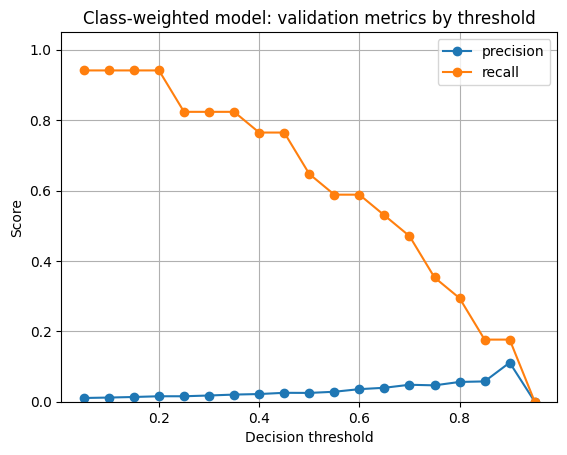

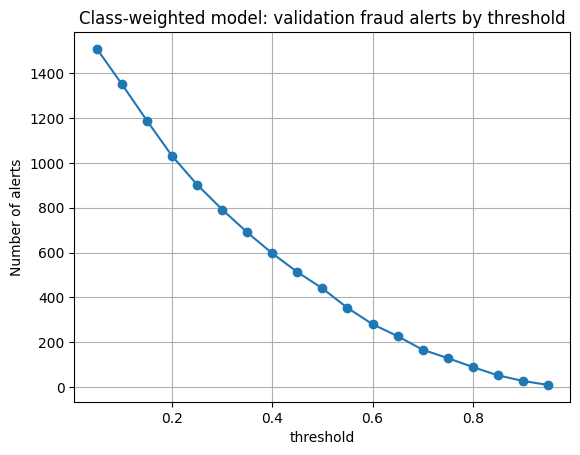

In [28]:
# Visualise the validation precision-recall trade-off.
ax = weighted_threshold_results.plot(
    x='threshold',
    y=['precision', 'recall'],
    marker='o'
)
ax.set_xlabel('Decision threshold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_title('Class-weighted model: validation metrics by threshold')
plt.grid(True)
plt.show()

# Also inspect how the number of alerts changes.
weighted_threshold_results.plot(
    x='threshold',
    y='fraud_alerts',
    marker='o',
    legend=False,
    title='Class-weighted model: validation fraud alerts by threshold'
)
plt.ylabel('Number of alerts')
plt.grid(True)
plt.show()

### 8.2 Select a threshold using the bank's constraints

We prefer the **highest threshold** that meets both constraints, because it gives the fewest alerts among the tested thresholds while maintaining the required recall.

If no tested threshold satisfies both constraints, the code reports that honestly and chooses a clearly labelled best-effort threshold for further investigation. This does not mean the model has met the bank's requirements.

In [29]:
MIN_RECALL = 0.90
MAX_ALERTS = 100

feasible_thresholds = weighted_threshold_results[
    (weighted_threshold_results['recall'] >= MIN_RECALL) &
    (weighted_threshold_results['fraud_alerts'] <= MAX_ALERTS)
]

if not feasible_thresholds.empty:
    selected_threshold = float(feasible_thresholds.sort_values('threshold').iloc[-1]['threshold'])
    print('A validation threshold satisfies both constraints.')
else:
    print('No tested validation threshold satisfies both constraints.')

    # Best effort: among thresholds with <= MAX_ALERTS, keep the one
    # with the highest recall. If none fit the alert limit, minimise alerts.
    under_alert_limit = weighted_threshold_results[
        weighted_threshold_results['fraud_alerts'] <= MAX_ALERTS
    ]

    if not under_alert_limit.empty:
        best_row = under_alert_limit.sort_values(
            ['recall', 'threshold'],
            ascending=[False, False]
        ).iloc[0]
    else:
        best_row = weighted_threshold_results.sort_values(
            ['fraud_alerts', 'recall'],
            ascending=[True, False]
        ).iloc[0]

    selected_threshold = float(best_row['threshold'])
    print('Using a best-effort threshold for diagnosis, not as a successful solution.')

print('Selected threshold:', selected_threshold)
print(weighted_threshold_results.loc[
    weighted_threshold_results['threshold'] == round(selected_threshold, 2)
].to_string(index=False))

No tested validation threshold satisfies both constraints.
Using a best-effort threshold for diagnosis, not as a successful solution.
Selected threshold: 0.8
 threshold  precision   recall  false_positives  false_negatives  fraud_alerts
       0.8    0.05618 0.294118               84               12            89


### 8.3 Evaluate the selected threshold once on the untouched test set

Do not go back and change the threshold based on these test results. The test set is our final estimate of how the chosen approach performs on unseen data.

In [30]:
test_fraud_scores = weighted_tuning_pipeline.predict_proba(X_test)[:, 1]
weighted_tuned_pred = (test_fraud_scores >= selected_threshold).astype(int)

weighted_tuned_results = evaluate_classifier(
    y_test,
    weighted_tuned_pred,
    f'Class-weighted logistic regression (threshold={selected_threshold:.2f})'
)

tn, fp, fn, tp = confusion_matrix(
    y_test, weighted_tuned_pred, labels=[0, 1]
).ravel()

test_alerts = int(fp + tp)
print('\nOperational check on the test set:')
print('Recall target met:', weighted_tuned_results['recall'] >= MIN_RECALL)
print('Alert target met:', test_alerts <= MAX_ALERTS)
print('Total fraud alerts:', test_alerts)

model        Class-weighted logistic regression (threshold=...
accuracy                                                 0.942
precision                                             0.056075
recall                                                0.285714
f1                                                     0.09375

Confusion matrix [[TN, FP], [FN, TP]]:
[[1878  101]
 [  15    6]]

Operational check on the test set:
Recall target met: False
Alert target met: False
Total fraud alerts: 107


### Your turn 5 — interpret threshold tuning

1. Which threshold gave the best validation trade-off?
2. Did any validation threshold meet both bank constraints?
3. What happened to false positives and false negatives as the threshold increased?
4. Did the selected threshold meet both constraints on the untouched test set?
5. Why must we not keep adjusting the threshold after looking at test results?

**Research habit:** If no threshold meets both targets, that is a useful result. It tells us threshold tuning alone may not be enough; we may need better features, a stronger model, or a better ranking of fraud risk.

In [31]:
comparison = pd.DataFrame([
    {'model': 'Baseline logistic regression', **{k: baseline_results[k] for k in ['accuracy', 'precision', 'recall', 'f1']}},
    {'model': 'SMOTE + logistic regression', **{k: smote_results[k] for k in ['accuracy', 'precision', 'recall', 'f1']}},
    {'model': 'Class-weighted logistic regression (default threshold)', **{k: weighted_results[k] for k in ['accuracy', 'precision', 'recall', 'f1']}},
    {'model': 'Class-weighted logistic regression (tuned threshold)', **{k: weighted_tuned_results[k] for k in ['accuracy', 'precision', 'recall', 'f1']}},
]).set_index('model')

comparison

,accuracy,precision,recall,f1
model,,,,
Baseline logistic regression,0.9900,1.000000,0.047619,0.090909
SMOTE + logistic regression,0.7580,0.036072,0.857143,0.069231
Class-weighted logistic regression (default threshold),0.7535,0.037255,0.904762,0.071563
Class-weighted logistic regression (tuned threshold),0.9420,0.056075,0.285714,0.093750


### Important evaluation note

The three approaches above use the same held-out test set, so their results are directly comparable for this fixed experiment. In a more complete study, use stratified cross-validation with preprocessing and resampling fitted inside each training fold, tune decisions using validation data, and keep a final test set untouched until the end. Also remember that this is simulated data: it is useful for learning the workflow, not for estimating real-world bank performance.

## 10. Experiment 5 — Random Forest

**Question:** Can a nonlinear tree-based model separate legitimate and fraudulent transactions better than Logistic Regression?

A Random Forest trains many decision trees on varied samples and feature subsets, then combines their predictions. Unlike Logistic Regression, it can learn nonlinear patterns and feature interactions without us manually creating them.

**Why no scaler?** Tree-based models split on feature values and generally do not need standardisation.

**Evaluation discipline:** We create a validation split from the original training data, select the threshold using validation only, and evaluate the chosen model once on the untouched test set. We will not tune using test results.

We will keep the bank's illustrative targets:
- Recall at least 90%.
- No more than 100 alerts in the 2,000-row evaluation set.

These are exercise constraints, not real-world daily alert volumes.

### 10.1 Train Random Forest on the fit split

We reuse `X_fit`, `X_val`, `y_fit`, and `y_val` created earlier. The model sees only the fit split at training time. `class_weight='balanced'` gives greater importance to the minority fraud class.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_fit, y_fit)

print("Random Forest trained.")
print("Fit rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Final test rows (still untouched):", len(X_test))

### 10.2 Choose a decision threshold using validation data

We inspect probability scores on validation data only. For each threshold, we calculate precision, recall, false positives, false negatives, and total alerts.

In [ ]:
rf_val_scores = rf_model.predict_proba(X_val)[:, 1]

rf_threshold_rows = []
for threshold in np.arange(0.05, 1.00, 0.05):
    val_pred = (rf_val_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, val_pred, labels=[0, 1]).ravel()

    rf_threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_val, val_pred, zero_division=0),
        "recall": recall_score(y_val, val_pred, zero_division=0),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "fraud_alerts": int(fp + tp)
    })

rf_threshold_results = pd.DataFrame(rf_threshold_rows)
print("Validation PR-AUC:", round(average_precision_score(y_val, rf_val_scores), 4))
rf_threshold_results

In [ ]:
ax = rf_threshold_results.plot(
    x="threshold",
    y=["precision", "recall"],
    marker="o"
)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Random Forest: validation precision and recall")
plt.grid(True)
plt.show()

rf_threshold_results.plot(
    x="threshold",
    y="fraud_alerts",
    marker="o",
    legend=False,
    title="Random Forest: validation fraud alerts by threshold"
)
plt.ylabel("Number of alerts")
plt.grid(True)
plt.show()

### 10.3 Select the threshold without looking at test results

We first look for thresholds meeting both constraints. If none does, we choose a clearly labelled best-effort threshold: among thresholds under the alert cap, select the one with the highest recall. This is not the same as meeting the bank's requirements.

In [ ]:
rf_feasible = rf_threshold_results[
    (rf_threshold_results["recall"] >= MIN_RECALL) &
    (rf_threshold_results["fraud_alerts"] <= MAX_ALERTS)
]

if not rf_feasible.empty:
    rf_selected_threshold = float(
        rf_feasible.sort_values("threshold").iloc[-1]["threshold"]
    )
    print("A validation threshold satisfies both constraints.")
else:
    print("No tested validation threshold satisfies both constraints.")
    rf_under_alert_limit = rf_threshold_results[
        rf_threshold_results["fraud_alerts"] <= MAX_ALERTS
    ]

    if not rf_under_alert_limit.empty:
        rf_best_row = rf_under_alert_limit.sort_values(
            ["recall", "threshold"],
            ascending=[False, False]
        ).iloc[0]
    else:
        rf_best_row = rf_threshold_results.sort_values(
            ["fraud_alerts", "recall"],
            ascending=[True, False]
        ).iloc[0]

    rf_selected_threshold = float(rf_best_row["threshold"])
    print("Using a best-effort threshold for diagnosis.")

print("Selected validation threshold:", rf_selected_threshold)
print(
    rf_threshold_results[
        rf_threshold_results["threshold"] == rf_selected_threshold
    ].to_string(index=False)
)

### 10.4 Final Random Forest evaluation — untouched test set

We now apply the already-selected threshold to the test probabilities exactly once. Do not adjust the threshold based on these test results.

In [ ]:
rf_test_scores = rf_model.predict_proba(X_test)[:, 1]
rf_test_pred = (rf_test_scores >= rf_selected_threshold).astype(int)

rf_results = evaluate_classifier(
    y_test,
    rf_test_pred,
    f"Random Forest (threshold={rf_selected_threshold:.2f})"
)

rf_test_tn, rf_test_fp, rf_test_fn, rf_test_tp = confusion_matrix(
    y_test, rf_test_pred, labels=[0, 1]
).ravel()
rf_test_alerts = int(rf_test_fp + rf_test_tp)

print("\\nRandom Forest test PR-AUC:", round(
    average_precision_score(y_test, rf_test_scores), 4
))
print("Total fraud alerts:", rf_test_alerts)
print("Recall target met:", rf_results["recall"] >= MIN_RECALL)
print("Alert target met:", rf_test_alerts <= MAX_ALERTS)

### 10.5 Compare Random Forest with the previous models

The comparison uses the same held-out test set. Treat this as one fixed synthetic-data experiment; do not repeatedly tune against the test set.

In [ ]:
comparison = pd.DataFrame([
    {"model": "Baseline logistic regression", **{k: baseline_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": "SMOTE + logistic regression", **{k: smote_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": "Class-weighted logistic regression (default threshold)", **{k: weighted_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": "Class-weighted logistic regression (tuned threshold)", **{k: weighted_tuned_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": f"Random Forest (threshold={rf_selected_threshold:.2f})", **{k: rf_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
]).set_index("model")

comparison.sort_values("recall", ascending=False)

### Your turn 6 — quick interpretation

1. Did Random Forest improve recall compared with class-weighted Logistic Regression?
2. How many false positives did it produce?
3. Did its validation threshold satisfy both operational constraints?
4. Did its test result support the validation-based choice?
5. Based on PR-AUC and the confusion matrix, is it a better candidate for the next experiment?

**Remember:** A more complex model is not automatically a better model. We need evidence from validation and the untouched test set.

## 11. Experiment 6 — Logistic Regression with engineered interactions

**Question:** Can manually adding feature interactions help a linear model capture relationships that ordinary Logistic Regression misses?

A linear model can learn a weighted combination of input columns. By adding product features, we give it extra columns that represent relationships between pairs of original features.

We will test three hypotheses:
- A transaction's amount may matter differently when transaction frequency is high.
- Failed attempts may be more concerning when the device-change score is high.
- Merchant risk may matter differently for transactions far from the user's usual location.

These are hypotheses, not guaranteed useful features. We will compare results rather than assume they help.

**Leakage control:** These are deterministic transformations, not statistics learned from the data. We apply the same function separately to fit, validation and test sets. The scaler and classifier are fitted only on the fit split.

### 11.1 Create interaction features

In [ ]:
def add_interaction_features(data):
    data = data.copy()

    data["amount_x_frequency"] = (
        data["transaction_amount"] * data["transactions_per_hour"]
    )
    data["failed_attempts_x_device_change"] = (
        data["failed_attempts"] * data["device_change_score"]
    )
    data["merchant_risk_x_distance"] = (
        data["merchant_risk"] * data["distance_from_usual_km"]
    )

    return data

X_fit_interactions = add_interaction_features(X_fit)
X_val_interactions = add_interaction_features(X_val)
X_test_interactions = add_interaction_features(X_test)

print("Original feature count:", X_fit.shape[1])
print("Feature count with interactions:", X_fit_interactions.shape[1])
print("Fit / validation / test shapes:")
print(X_fit_interactions.shape, X_val_interactions.shape, X_test_interactions.shape)

### 11.2 Train class-weighted Logistic Regression

We use a pipeline so the scaler learns its means and standard deviations from the fit split only. Class weighting helps the model pay more attention to fraud examples.

In [ ]:
interaction_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

interaction_pipeline.fit(X_fit_interactions, y_fit)
print("Interaction-feature Logistic Regression trained.")

### 11.3 Select a threshold using validation data only

We use the same threshold grid and bank constraints as the previous experiments. The test set remains untouched.

In [ ]:
interaction_val_scores = interaction_pipeline.predict_proba(
    X_val_interactions
)[:, 1]

interaction_threshold_rows = []
for threshold in np.arange(0.05, 1.00, 0.05):
    val_pred = (interaction_val_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    interaction_threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_val, val_pred, zero_division=0),
        "recall": recall_score(y_val, val_pred, zero_division=0),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "fraud_alerts": int(fp + tp)
    })

interaction_threshold_results = pd.DataFrame(interaction_threshold_rows)
print(
    "Validation PR-AUC:",
    round(average_precision_score(y_val, interaction_val_scores), 4)
)
interaction_threshold_results

In [ ]:
ax = interaction_threshold_results.plot(
    x="threshold",
    y=["precision", "recall"],
    marker="o"
)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Interaction Logistic Regression: validation precision and recall")
plt.grid(True)
plt.show()

interaction_threshold_results.plot(
    x="threshold",
    y="fraud_alerts",
    marker="o",
    legend=False,
    title="Interaction Logistic Regression: validation alerts by threshold"
)
plt.ylabel("Number of alerts")
plt.grid(True)
plt.show()

### 11.4 Select the threshold without test-set tuning

If any validation threshold meets both constraints, choose the highest such threshold. Otherwise, choose the best-effort threshold with the highest recall among those under the alert cap. If none is under the cap, choose the threshold with the fewest alerts.

In [ ]:
interaction_feasible = interaction_threshold_results[
    (interaction_threshold_results["recall"] >= MIN_RECALL) &
    (interaction_threshold_results["fraud_alerts"] <= MAX_ALERTS)
]

if not interaction_feasible.empty:
    interaction_selected_threshold = float(
        interaction_feasible.sort_values("threshold").iloc[-1]["threshold"]
    )
    print("A validation threshold satisfies both constraints.")
else:
    print("No tested validation threshold satisfies both constraints.")
    interaction_under_cap = interaction_threshold_results[
        interaction_threshold_results["fraud_alerts"] <= MAX_ALERTS
    ]

    if not interaction_under_cap.empty:
        interaction_best_row = interaction_under_cap.sort_values(
            ["recall", "threshold"],
            ascending=[False, False]
        ).iloc[0]
    else:
        interaction_best_row = interaction_threshold_results.sort_values(
            ["fraud_alerts", "recall"],
            ascending=[True, False]
        ).iloc[0]

    interaction_selected_threshold = float(
        interaction_best_row["threshold"]
    )
    print("Using a best-effort threshold for diagnosis.")

print("Selected validation threshold:", interaction_selected_threshold)
interaction_threshold_results[
    interaction_threshold_results["threshold"] == interaction_selected_threshold
]

### 11.5 Final evaluation — untouched test set

Apply the validation-selected threshold once to the untouched test set. Do not adjust it after seeing these results.

In [ ]:
interaction_test_scores = interaction_pipeline.predict_proba(
    X_test_interactions
)[:, 1]
interaction_test_pred = (
    interaction_test_scores >= interaction_selected_threshold
).astype(int)

interaction_results = evaluate_classifier(
    y_test,
    interaction_test_pred,
    f"Interaction Logistic Regression (threshold={interaction_selected_threshold:.2f})"
)

interaction_test_tn, interaction_test_fp, interaction_test_fn, interaction_test_tp = (
    confusion_matrix(y_test, interaction_test_pred, labels=[0, 1]).ravel()
)
interaction_test_alerts = int(interaction_test_fp + interaction_test_tp)

print("\\nTest PR-AUC:", round(
    average_precision_score(y_test, interaction_test_scores), 4
))
print("Total fraud alerts:", interaction_test_alerts)
print("Recall target met:", interaction_results["recall"] >= MIN_RECALL)
print("Alert target met:", interaction_test_alerts <= MAX_ALERTS)

### 11.6 Compare all models on the same test set

In [ ]:
comparison = pd.DataFrame([
    {"model": "Baseline logistic regression", **{k: baseline_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": "SMOTE + logistic regression", **{k: smote_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": "Class-weighted logistic regression (default threshold)", **{k: weighted_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": f"Class-weighted logistic regression (tuned threshold={selected_threshold:.2f})", **{k: weighted_tuned_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": f"Random Forest (threshold={rf_selected_threshold:.2f})", **{k: rf_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
    {"model": f"Interaction Logistic Regression (threshold={interaction_selected_threshold:.2f})", **{k: interaction_results[k] for k in ["accuracy", "precision", "recall", "f1"]}},
]).set_index("model")

comparison.sort_values("recall", ascending=False)

### Your turn 7 — quick interpretation

1. Did interaction features improve test recall compared with ordinary class-weighted Logistic Regression?
2. Did they improve the alert-volume trade-off compared with Random Forest?
3. Did validation and test results tell a similar story?
4. Which model is the strongest candidate so far, considering both recall and alerts?

**Research habit:** More features do not automatically mean a better model. We need evidence that the added interactions improve generalisation.

## 9. Final reflection — record your evidence

Answer these in your own words before marking the notebook complete:

1. Why must the train/test split happen before fitting a scaler or applying SMOTE?
2. Why do we scale before SMOTE for distance-based neighbour selection?
3. Why must SMOTE never be applied to the test set?
4. What does precision tell a fraud operations team?
5. What does recall tell the team?
6. When can F1-score be insufficient as the only model-selection metric?
7. What would you test next: a different model, better features, or another validation-based experiment? State a hypothesis.

### Completion checklist

- [ ] I ran every code cell successfully.
- [ ] I can explain each confusion-matrix value.
- [ ] I compared baseline and SMOTE results without relying on accuracy alone.
- [ ] I can explain why the test set remained untouched.
- [ ] I wrote a short conclusion and one next experiment.

**Research habit:** Record the random seed, data-generation settings, model configuration, metrics, and limitations whenever you report an experiment. Synthetic data is useful for practice, but it does not establish real-world fraud performance.